# Response of the redshift-space power spectrum

Maps of how the galaxy power spectrum a survey observes responds to each parameter.

A survey observes the spectrum as a function of the wave number and of $\mu$, the cosine of the angle to the line of sight. Two effects make it anisotropic. Peculiar velocities add the Kaiser factor,

$$
P_g(k, \mu) = (b + f \mu^2)^2 P(k),
$$

and the survey turns redshifts and angles into distances with a reference cosmology, which rescales the true wave numbers (Alcock-Paczynski):

$$
P_\mathrm{obs}(k_\mathrm{ref}, \mu_\mathrm{ref}) = \frac{P_g(k, \mu)}{q_\perp^2 q_\parallel}, \qquad
q_\perp = \frac{D_A}{D_{A,\mathrm{ref}}}, \qquad
q_\parallel = \frac{H_\mathrm{ref}}{H} .
$$

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from discoeb import LCDM, background_history, conformal_ages, solve_eb

REDSHIFT = 1.0
K = np.geomspace(1.0e-4, 1.0, 128)  # wave numbers of the solve, 1/Mpc
K_REF = K[4:-4]  # of the map: the rescaled ones stay inside the solve's
MU = np.linspace(0.0, 1.0, 65)

## The cosmology and its parameters

The Planck 2018 best fit is the reference. The parameters are five of the cosmology and the galaxy bias, $b = 1.5$.

In [2]:
h = 0.6732117
planck = LCDM(
    Omegam=(0.02238280 + 0.1201075) / h**2,
    Omegab=0.02238280 / h**2,
    H0=100.0 * h,
    A_s=2.100549e-9,
    n_s=0.9660499,
    Tcmb=2.7255,
    YHe=0.2454006,
    Neff=3.046,
)
PARAMETERS = {  # key: label; the last is the galaxy bias
    "H0": "H_0",
    "Omegam": r"\Omega_m",
    "Omegab": r"\Omega_b",
    "Neff": r"N_\mathrm{eff}",
    "n_s": "n_s",
    "bias": "b",
}
theta = jnp.asarray([getattr(planck, key) for key in list(PARAMETERS)[:-1]] + [1.5])

## Save times

`solve_eb` records at conformal times, and a derivative of its values holds those times fixed. A result at a fixed redshift needs the scale factor kept beside the other quantities at a few save times around it. An interpolation in `a` then gives every quantity at exactly that redshift, and JAX carries the shift of $a(\tau)$ with the parameters.

In [3]:
# Five save times around the redshift, from the reference background.
A_SAMPLE = 1.0 / (1.0 + REDSHIFT)
a_bg, tau_bg = background_history(planck)
TAU = np.interp(A_SAMPLE * np.linspace(0.9, 1.1, 5), a_bg, tau_bg)

## Linear theory at the redshift

Everything comes from one `solve_eb`. The density contrasts and their rates give $P$ and the growth rate

$$
f = -\frac{k \, (z + f_b v_b)}{a H \, \delta}, \qquad f_b = \frac{\Omega_b}{\Omega_m},
$$

the expansion rate `adotoa` gives $a H$, and the conformal time at the sample's scale factor gives the comoving distance $\tau_0 - \tau(a)$.

In [4]:
def linear_theory(cosmology):
    """``P(k)``, the growth rate ``f(k)``, the comoving distance and ``a H`` at the redshift."""

    values = solve_eb(
        cosmology, K, TAU, keep=("clxc", "clxb", "z", "vb", "adotoa", "a")
    )
    # from the save times to the sample's scale factor: each (k,)
    a = values[0, -1, 0]
    clxc, clxb, z, vb, adotoa, _ = jax.vmap(
        jax.vmap(lambda v: jnp.interp(A_SAMPLE, a, v))
    )(values[0])

    f_b = cosmology.Omegab / cosmology.Omegam
    delta = (1.0 - f_b) * clxc + f_b * clxb
    growth_rate = -K * (z + f_b * vb) / (adotoa * delta)
    primordial = cosmology.A_s * (K / cosmology.k_p) ** (cosmology.n_s - 1.0)
    pk = 2.0 * jnp.pi**2 / K**3 * primordial * delta**2
    distance = conformal_ages(cosmology)[0] - jnp.interp(A_SAMPLE, a, TAU)
    return pk, growth_rate, distance, adotoa[0]

The reference distance and expansion rate, which the survey assumes:

In [5]:
_, _, distance_ref, aH_ref = linear_theory(planck)

## The observed spectrum

A reference $(k_\mathrm{ref}, \mu_\mathrm{ref})$ maps to the true

$$
k = \frac{k_\mathrm{ref}}{q_\perp} \sqrt{1 + \mu_\mathrm{ref}^2 \left(\frac{q_\perp^2}{q_\parallel^2} - 1\right)},
\qquad
\mu = \mu_\mathrm{ref} \, \frac{q_\perp}{q_\parallel} \left[1 + \mu_\mathrm{ref}^2 \left(\frac{q_\perp^2}{q_\parallel^2} - 1\right)\right]^{-1/2} .
$$

In [6]:
def observed_power(theta):
    """``P_obs(k_ref, mu_ref)`` in Mpc^3, ``(len(K_REF), len(MU))``."""

    *cosmological, bias = theta
    pk, growth_rate, distance, aH = linear_theory(
        planck.replace(**dict(zip(PARAMETERS, cosmological)))
    )
    q_perp, q_par = distance / distance_ref, aH_ref / aH
    stretch = jnp.sqrt(1.0 + MU**2 * ((q_perp / q_par) ** 2 - 1.0))
    k = K_REF[:, None] / q_perp * stretch  # the true wave number and angle
    mu = MU * q_perp / q_par / stretch
    pk = jnp.exp(jnp.interp(jnp.log(k), np.log(K), jnp.log(pk)))
    growth_rate = jnp.interp(jnp.log(k), np.log(K), growth_rate)
    return (bias + growth_rate * mu**2) ** 2 * pk / (q_perp**2 * q_par)

## The response

$\partial \ln P_\mathrm{obs} / \partial \ln p$ over the $(k, \mu)$ plane, from one `jax.jacfwd`.

In [7]:
power = observed_power(theta)
jacobian = jax.jacfwd(observed_power)(theta)  # (k, mu, parameter)
response = np.asarray(theta * jacobian / power[..., None])  # d ln P / d ln p

In [8]:
print(f"d ln P_obs / d ln p at z = {REDSHIFT}, across (mu = 0) and along (mu = 1)")
print(f"{'k [1/Mpc]':>10}  {'mu':>3}" + "".join(f"{key:>9}" for key in PARAMETERS))
for i in range(6, len(K_REF), 22):
    for j in (0, -1):
        row = "".join(f"{v:9.3f}" for v in response[i, j])
        print(f"{K_REF[i]:10.3e}  {MU[j]:3.0f}{row}")

d ln P_obs / d ln p at z = 1.0, across (mu = 0) and along (mu = 1)
 k [1/Mpc]   mu       H0   Omegam   Omegab     Neff      n_s     bias
 2.065e-04    0   -0.208   -1.077    0.000   -0.002   -5.303    2.000
 2.065e-04    1   -0.144   -0.765    0.000   -0.002   -5.303    1.262
 1.018e-03    0   -0.152   -1.031    0.000   -0.014   -3.762    2.000
 1.018e-03    1   -0.088   -0.728    0.000   -0.014   -3.762    1.262
 5.021e-03    0    0.218   -0.728   -0.003   -0.098   -2.221    2.000
 5.021e-03    1    0.267   -0.495   -0.003   -0.098   -2.221    1.263
 2.476e-02    0    1.291    0.582   -0.297   -0.297   -0.679    2.000
 2.476e-02    1    1.167    0.487   -0.297   -0.298   -0.679    1.263
 1.221e-01    0    2.340    1.619   -0.740   -0.551    0.862    2.000
 1.221e-01    1    2.030    1.420   -0.740   -0.553    0.862    1.263
 6.019e-01    0    2.902    2.268   -0.764   -0.558    2.404    2.000
 6.019e-01    1    2.606    1.882   -0.764   -0.560    2.404    1.263


## The maps

One polar "eye" per parameter: the angle to the line of sight goes around, with the line of sight pointing up, and $\log k$ goes outwards.

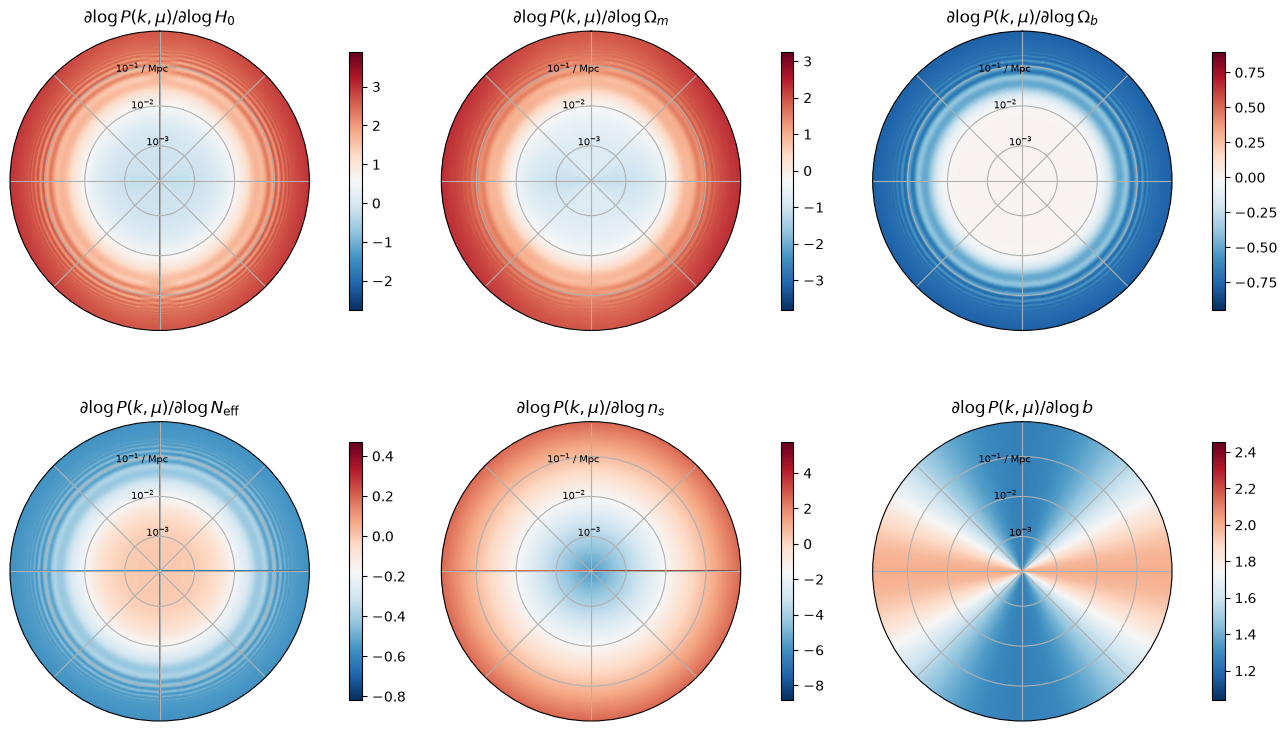

In [9]:
# One eye per parameter: the angle to the line of sight around, log k outwards.
angle = np.arccos(MU)
angle = np.concatenate(
    [angle, np.pi - angle[::-1], np.pi + angle, 2 * np.pi - angle[::-1]]
)
fig, axes = plt.subplots(2, 3, figsize=(13, 8.5), subplot_kw={"projection": "polar"})
for i, (ax, label) in enumerate(zip(axes.flat, PARAMETERS.values())):
    quadrant = response[..., i]
    eye = np.concatenate([quadrant, quadrant[:, ::-1], quadrant, quadrant[:, ::-1]], 1)
    centre = np.median(quadrant)
    limit = 3.0 * np.std(quadrant) + 1.0e-3
    mesh = ax.pcolormesh(
        angle,
        np.log10(K_REF),
        eye,
        cmap="RdBu_r",
        vmin=centre - limit,
        vmax=centre + limit,
        shading="gouraud",
    )
    fig.colorbar(mesh, ax=ax, shrink=0.6, pad=0.1)
    ax.set_theta_zero_location("N")
    ax.set_xticklabels([])
    ax.set_rticks([-3, -2, -1])
    ax.set_yticklabels([r"$10^{-3}$", r"$10^{-2}$", r"$10^{-1}$ / Mpc"], size=7)
    ax.set_title(rf"$\partial \log P(k, \mu) / \partial \log {label}$")
fig.tight_layout()
plt.show()